# Final Assignment (Basic Track): Touchdown
NLP Track · Epoch Zero Bootcamp

## Mission Briefing

Crew, this is it. The last stretch.

Mary has come a long way. She can read, sort and remember. Now she carries a pre-trained brain that has read a mountain of text, and she is one fine-tune away frombecoming a specialist.

There is one last problem. The journey has been long, and the crew's morale is slipping.Mission Control needs an
Emotion Monitor: a system that reads a crew member's logmessage and tells Mary whether they are feeling sadness, joy, love, anger, fear or surprise. If Mary can spot a crew member in trouble before it's too late, everyone makes itto the landing.

Seven levels stand between you and touchdown. Clear them all and Mary lands.

## Rules of the Mission

* Everything is done in **one Google Colab notebook**. Switch on a GPU: Runtime >Change runtime type > T4 GPU.

* **Every level requires code**. Write short # comments where a level asks for yourobservation.

* Use only what's in the Section 4 topics: pipeline, tokenizer, model,
Trainer ,freezing, fine-tuning, evaluation.

* Before submitting, do **Runtime > Restart and run all**. Everything must run top tobottom with the outputs visible.

* Everyone works with the **same data and the same model**:
distilbert-base-uncased and the Emotion dataset below.

In [1]:
# Starter Cell (copy this as your first cell)

!pip install -q transformers datasets evaluate accelerate scikit-learn

import numpy as np
import torch
from collections import Counter
from datasets import load_dataset
from transformers import (pipeline, AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer)

MODEL = "distilbert-base-uncased"
LABELS = ["sadness", "joy", "love", "anger", "fear", "surprise"]
id2label = {i: l for i, l in enumerate(LABELS)}
label2id = {l: i for i, l in id2label.items()}
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device) # should say cuda

Running on: cpu


## Level 0: Mission Briefing

The crew's logs are stored in the **Emotion dataset**. Load it with:

dataset = load_dataset("dair-ai/emotion")train_raw = dataset["train"].shuffle(seed=42).select(range(2000))test_raw = dataset["test"].shuffle(seed=42).select(range(500))

We use only a small slice so everything runs fast.

## Tasks
1. Print the number of examples in train_raw and test_raw.
2. Print the first 3 training texts together with their emotion names (labels are stored asnumbers 0 to 5; use id2label to convert).
3. Using Counter , print how many training examples there are per emotion name.
4. In a comment: which emotion is the most common and which is the rarest? Do youexpect the model to find the rare one harder?

In [3]:
# Load the dataset and print its size

import time
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

dataset = load_dataset("dair-ai/emotion")

train_raw = dataset["train"].shuffle(seed=42).select(range(2000))
test_raw = dataset["test"].shuffle(seed=42).select(range(500))

print("Number of training examples:", len(train_raw))
print("Number of test examples:", len(test_raw))

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Number of training examples: 2000
Number of test examples: 500


In [4]:
# Print the first three training examples

for i in range(3):
    example = train_raw[i]

    print(f"Example {i + 1}")
    print("Text:", example["text"])
    print("Emotion:", id2label[example["label"]])
    print("-" * 60)

Example 1
Text: while cycling in the country
Emotion: fear
------------------------------------------------------------
Example 2
Text: i had pocket qq and was feeling pretty confident lol
Emotion: joy
------------------------------------------------------------
Example 3
Text: i am in no way complaining or whining or feeling ungrateful
Emotion: sadness
------------------------------------------------------------


In [5]:
# Count training examples per emotion

emotion_counts = Counter(
    id2label[label] for label in train_raw["label"]
)

print("Training examples per emotion:\n")

for emotion in LABELS:
    print(f"{emotion:10s}: {emotion_counts[emotion]}")

most_common = max(emotion_counts, key=emotion_counts.get)
rarest = min(emotion_counts, key=emotion_counts.get)

print("\nMost common emotion:", most_common)
print("Rarest emotion:", rarest)

Training examples per emotion:

sadness   : 598
joy       : 663
love      : 161
anger     : 261
fear      : 247
surprise  : 70

Most common emotion: joy
Rarest emotion: surprise


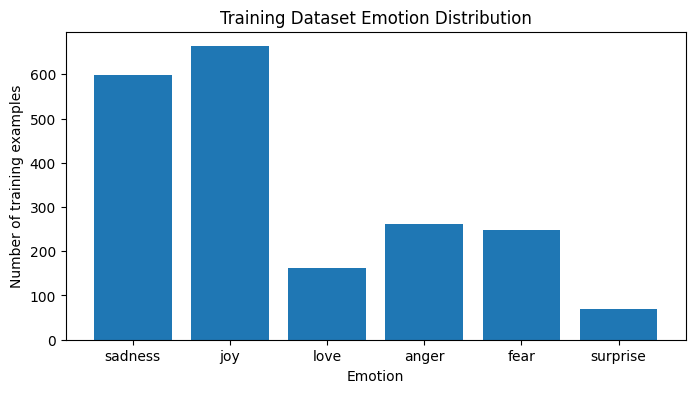

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.bar(
    LABELS,
    [emotion_counts[label] for label in LABELS]
)

plt.xlabel("Emotion")
plt.ylabel("Number of training examples")
plt.title("Training Dataset Emotion Distribution")
plt.show()

In [7]:
# Joy is expected to be the most common emotion, while surprise
# is expected to be the rarest. Verify this using the counts above.
# The model may find the rarest emotion harder to classify because
# it has fewer training examples from which to learn its patterns.

## Level 1: Cold Boot

Before training anything, let's see what a ready-made model can do. Mary boots up with ageneral sentiment model.

## Tasks
1. Create a pipeline("sentiment-analysis").
2. Run it on these five crew logs and print the label and score of each:

logs = [ "The hydroponics bay finally bloomed and I can't stop smiling.", "I haven't heard my family's voices in months, and the silence is crushing me.", "Someone sabotaged the coolant line again. I am absolutely furious.", "The hull just made a sound I've never heard before. I'm terrified.", "Wait, the signal is coming from inside our own system? I did not see that coming!",]

3. Write one sentence in a comment: why can this pipeline not tell the difference between the third log (anger) and the fourth log (fear)? What would we need tochange?

In [8]:
# Create a sentiment pipeline and classify crew logs

sentiment_classifier = pipeline(
    "sentiment-analysis",
    device=0 if torch.cuda.is_available() else -1
)

logs = [
    "The hydroponics bay finally bloomed and I can't stop smiling.",
    "I haven't heard my family's voices in months, and the silence is crushing me.",
    "Someone sabotaged the coolant line again. I am absolutely furious.",
    "The hull just made a sound I've never heard before. I'm terrified.",
    "Wait, the signal is coming from inside our own system? I did not see that coming!",
]

results = sentiment_classifier(logs)

for i, (log, result) in enumerate(zip(logs, results)):
    print(f"Log {i + 1}: {log}")
    print("Label:", result["label"])
    print(f"Score: {result['score']:.4f}")
    print("-" * 70)

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Log 1: The hydroponics bay finally bloomed and I can't stop smiling.
Label: POSITIVE
Score: 0.9996
----------------------------------------------------------------------
Log 2: I haven't heard my family's voices in months, and the silence is crushing me.
Label: NEGATIVE
Score: 0.9978
----------------------------------------------------------------------
Log 3: Someone sabotaged the coolant line again. I am absolutely furious.
Label: NEGATIVE
Score: 0.9984
----------------------------------------------------------------------
Log 4: The hull just made a sound I've never heard before. I'm terrified.
Label: NEGATIVE
Score: 0.9958
----------------------------------------------------------------------
Log 5: Wait, the signal is coming from inside our own system? I did not see that coming!
Label: NEGATIVE
Score: 0.9992
----------------------------------------------------------------------


In [9]:
# The sentiment pipeline cannot distinguish anger from fear because
# both can be classified as NEGATIVE; we need to fine-tune a model
# with six emotion classes instead of two sentiment classes.

## Level 2: Learn the Alphabet

Mary's model only understands numbers. Time to meet the tokenizer.

## Tasks

1. Load AutoTokenizer.from_pretrained(MODEL).
2. For the first log above, print its **tokens**(tokenizer.tokenize) and its **token IDs**.
3. Find a word of your own choice that gets **split into sub-word pieces**. Print the wordand its pieces.
4. Tokenize these two sentences **together as a batch** with padding=True and return_tensors="pt". Print the input_ids and the attention_mask : ["Allsystems nominal.", "I miss the sound of rain on the roof back home."] In acomment, explain what the 0s in the attention mask mean.
5. Compute the token length of every text in train_raw. Print the **average** and **maximum** length. Pick a MAX_LEN (a sensible number that covers almost all texts),store it in a variable and justify it in a comment.

In [10]:
# Load the tokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL)

print("Tokenizer:", tokenizer.__class__.__name__)
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer: BertTokenizer
Vocabulary size: 30522


In [11]:
# Print tokens and token IDs

first_log = logs[0]

tokens = tokenizer.tokenize(first_log)

token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("Original text:")
print(first_log)

print("\nTokens:")
print(tokens)

print("\nToken IDs:")
print(token_ids)

print("\nToken IDs with special tokens:")
print(tokenizer(first_log)["input_ids"])

Original text:
The hydroponics bay finally bloomed and I can't stop smiling.

Tokens:
['the', 'hydro', '##pon', '##ics', 'bay', 'finally', 'bloom', '##ed', 'and', 'i', 'can', "'", 't', 'stop', 'smiling', '.']

Token IDs:
[1996, 18479, 26029, 6558, 3016, 2633, 13426, 2098, 1998, 1045, 2064, 1005, 1056, 2644, 5629, 1012]

Token IDs with special tokens:
[101, 1996, 18479, 26029, 6558, 3016, 2633, 13426, 2098, 1998, 1045, 2064, 1005, 1056, 2644, 5629, 1012, 102]


In [12]:
# Find a word split into subwords

word = "interplanetary"

pieces = tokenizer.tokenize(word)

print("Original word:", word)
print("Subword pieces:", pieces)
print("Number of pieces:", len(pieces))

Original word: interplanetary
Subword pieces: ['inter', '##plane', '##tary']
Number of pieces: 3


In [13]:
# Batch tokenization and attention masks

sentences = [
    "All systems nominal.",
    "I miss the sound of rain on the roof back home."
]

batch = tokenizer(
    sentences,
    padding=True,
    return_tensors="pt"
)

print("Input IDs:")
print(batch["input_ids"])

print("\nAttention mask:")
print(batch["attention_mask"])

print("\nInput shape:", batch["input_ids"].shape)

Input IDs:
tensor([[  101,  2035,  3001, 15087,  1012,   102,     0,     0,     0,     0,
             0,     0,     0,     0],
        [  101,  1045,  3335,  1996,  2614,  1997,  4542,  2006,  1996,  4412,
          2067,  2188,  1012,   102]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])

Input shape: torch.Size([2, 14])


In [14]:
# The 0s in the attention mask represent padding tokens added
# to make all sentences in the batch have the same length.
# The model should ignore these padding positions during attention.

In [15]:
# Compute average and maximum token lengths

token_lengths = [
    len(tokenizer(text)["input_ids"])
    for text in train_raw["text"]
]

print(f"Average token length: {np.mean(token_lengths):.2f}")
print("Maximum token length:", max(token_lengths))

print("95th percentile:", np.percentile(token_lengths, 95))
print("99th percentile:", np.percentile(token_lengths, 99))

MAX_LEN = 128

coverage = np.mean(
    np.array(token_lengths) <= MAX_LEN
) * 100

print("\nSelected MAX_LEN:", MAX_LEN)
print(f"Percentage of texts covered: {coverage:.2f}%")

# MAX_LEN = 128 is selected because it should cover almost all
# training texts while keeping GPU memory and computation manageable.
# The coverage printed above verifies this choice.

Average token length: 22.62
Maximum token length: 66
95th percentile: 46.0
99th percentile: 57.00999999999999

Selected MAX_LEN: 128
Percentage of texts covered: 100.00%


## Level 3: Open the Hood

Now look inside the brain Mary will be using.

## Tasks

1. Load the model with a fresh, untrained 6-class head:

model = AutoModelForSequenceClassification.from_pretrained( MODEL,num_labels=6, id2label=id2label, label2id=label2id)

2. Pass the sentence "I miss home so much." through the model (tokenize it, run themodel, get the **logits** ). Convert the logits to probabilities with **softmax** and print theprobability of each emotion name. In a comment: why are the probabilities nearlyequal right now?

3. Print the **total number of parameters** and the **number of trainable parameters**.

4. **Freeze** the pre-trained body so that only the new classification layers remain trainable:

for p in model.distilbert.parameters():
  
  p.requires_grad = False

Print the trainable parameters again, and print what
percentage
of all parameters is nowtrainable.

In [16]:
# Load DistilBERT with a fresh six-class head

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL,
    num_labels=6,
    id2label=id2label,
    label2id=label2id
)

model = model.to(device)

print(model)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [17]:
# Obtain probabilities before training

sentence = "I miss home so much."

inputs = tokenizer(
    sentence,
    return_tensors="pt"
).to(device)

model.eval()

with torch.no_grad():
    outputs = model(**inputs)

logits = outputs.logits

probabilities = torch.softmax(logits, dim=-1)

print("Input sentence:", sentence)

print("\nLogits:")
print(logits.cpu().numpy())

print("\nEmotion probabilities:")

for i, probability in enumerate(probabilities[0]):
    print(f"{id2label[i]:10s}: {probability.item():.4f}")

# The probabilities are approximately similar because the new
# classification head is randomly initialized and has not yet
# learned the relationship between text and emotion labels.

Input sentence: I miss home so much.

Logits:
[[-0.01423299 -0.11609924  0.08537591  0.14883748 -0.07455242 -0.06544839]]

Emotion probabilities:
sadness   : 0.1646
joy       : 0.1486
love      : 0.1818
anger     : 0.1937
fear      : 0.1549
surprise  : 0.1564


In [18]:
# Count total and trainable parameters

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 66,958,086
Trainable parameters: 66,958,086


In [19]:
# Freeze the pretrained body

for p in model.distilbert.parameters():
    p.requires_grad = False

frozen_trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

trainable_percentage = (
    frozen_trainable_params / total_params
) * 100

print(f"Total parameters: {total_params:,}")

print(
    f"Trainable parameters after freezing: "
    f"{frozen_trainable_params:,}"
)

print(f"Trainable percentage: {trainable_percentage:.4f}%")

Total parameters: 66,958,086
Trainable parameters after freezing: 595,206
Trainable percentage: 0.8889%


## Level 4: Two Routes to Mastery

The big one. Mary can learn in two ways. You will try both and compare.

## Setup tasks

1. Tokenize train_raw and test_raw with a function using truncation=True, padding="max_length" and your MAX_LEN , applied with .map(..., batched=True).
2. Write a compute_metrics function that returns **accuracy** (see Section 4 notes).

## Route A: Feature Extraction (frozen body)

3. Load a **fresh** model (same code as Level 3), freeze model.distilbert as above, andtrain with Trainer using:

Setting -  Value
learning_rate  -  1e-3
num_train_epochs  -  3
per_device_train_batch_size  -  32
report_to  -  "none"

Record the test accuracy from trainer.evaluate().

## Route B: Full Fine-Tuning (nothing frozen)

4. Load another **fresh** model, do **not** freeze anything, and train with:

Setting  -  Value
learning_rate  -  5e-5
num_train_epochs  -  3
per_device_train_batch_size  -  32
weight_decay  -  0.01
report_to  -  "none"

Record the test accuracy.

## Compare

5. Print a small comparison table: route name, trainable parameters, training time (use time.time() around trainer.train()), test accuracy.

6. In 2 to 3 lines of comments: which route won, which was faster, and why do you thinkthat happened?

Tip: if you see an error about eval_strategy , your library version is older. Use evaluation_strategy instead. If you run out of GPU memory, lower the batch size to16.


In [20]:
# Tokenize training and testing datasets

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LEN
    )

train_tokenized = train_raw.map(
    tokenize_function,
    batched=True
)

test_tokenized = test_raw.map(
    tokenize_function,
    batched=True
)

print(train_tokenized)
print(test_tokenized)

print(
    "\nInput length:",
    len(train_tokenized[0]["input_ids"])
)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
})
Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 500
})

Input length: 128


In [21]:
# Define evaluation metrics

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)

    return {"accuracy": accuracy}

In [22]:
# Release previously used GPU memory

import gc

del model
del sentiment_classifier

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [23]:
# Route A: Feature extraction (frozen body)

# Load a fresh model and freeze its body

torch.manual_seed(42)

model_a = AutoModelForSequenceClassification.from_pretrained(
    MODEL,
    num_labels=6,
    id2label=id2label,
    label2id=label2id
)

for p in model_a.distilbert.parameters():
    p.requires_grad = False

trainable_a = sum(
    p.numel() for p in model_a.parameters()
    if p.requires_grad
)

print(f"Route A trainable parameters: {trainable_a:,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Route A trainable parameters: 595,206


In [24]:
# Configure training arguments

training_args_a = TrainingArguments(
    output_dir="./route_a_results",

    learning_rate=1e-3,
    num_train_epochs=3,

    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,

    logging_strategy="epoch",
    save_strategy="no",

    report_to="none",
    seed=42
)

trainer_a = Trainer(
    model=model_a,
    args=training_args_a,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
    compute_metrics=compute_metrics
)

In [25]:
# Train and evaluate Route A

start_time = time.time()

train_result_a = trainer_a.train()

training_time_a = time.time() - start_time

results_a = trainer_a.evaluate()

accuracy_a = results_a["eval_accuracy"]

print("\n" + "=" * 50)
print("ROUTE A: FEATURE EXTRACTION")
print("=" * 50)

print(f"Trainable parameters: {trainable_a:,}")
print(f"Training time: {training_time_a:.2f} seconds")
print(f"Test accuracy: {accuracy_a * 100:.2f}%")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
63,1.480826
126,1.327289
189,1.264517


Training Loss,Validation Loss,Step,Accuracy
1.264517,1.194356,189,0.568000



ROUTE A: FEATURE EXTRACTION
Trainable parameters: 595,206
Training time: 1611.51 seconds
Test accuracy: 56.80%


In [26]:
# Move Route A to CPU

trainer_a.save_model("./route_a_model")

model_a.to("cpu")

# Release optimizer and scheduler references.
trainer_a.optimizer = None
trainer_a.lr_scheduler = None

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [27]:
# Route B: Full fine-tuning

# Load another fresh model

torch.manual_seed(42)

model_b = AutoModelForSequenceClassification.from_pretrained(
    MODEL,
    num_labels=6,
    id2label=id2label,
    label2id=label2id
)

trainable_b = sum(
    p.numel() for p in model_b.parameters()
    if p.requires_grad
)

print(f"Route B trainable parameters: {trainable_b:,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Route B trainable parameters: 66,958,086


In [28]:
# Configure training arguments

training_args_b = TrainingArguments(
    output_dir="./route_b_results",

    learning_rate=5e-5,
    num_train_epochs=3,

    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,

    weight_decay=0.01,

    logging_strategy="epoch",
    save_strategy="no",

    report_to="none",
    seed=42
)

trainer_b = Trainer(
    model=model_b,
    args=training_args_b,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
    compute_metrics=compute_metrics
)

In [29]:
# Train and evaluate Route B

start_time = time.time()

train_result_b = trainer_b.train()

training_time_b = time.time() - start_time

results_b = trainer_b.evaluate()

accuracy_b = results_b["eval_accuracy"]

print("\n" + "=" * 50)
print("ROUTE B: FULL FINE-TUNING")
print("=" * 50)

print(f"Trainable parameters: {trainable_b:,}")
print(f"Training time: {training_time_b:.2f} seconds")
print(f"Test accuracy: {accuracy_b * 100:.2f}%")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
63,1.303835
126,0.598353
189,0.345558


Training Loss,Validation Loss,Step,Accuracy
0.345558,0.411719,189,0.864000



ROUTE B: FULL FINE-TUNING
Trainable parameters: 66,958,086
Training time: 4014.46 seconds
Test accuracy: 86.40%


In [30]:
# Compare both routes

comparison = pd.DataFrame({
    "Route": [
        "A: Feature Extraction",
        "B: Full Fine-Tuning"
    ],

    "Trainable Parameters": [
        trainable_a,
        trainable_b
    ],

    "Training Time (seconds)": [
        training_time_a,
        training_time_b
    ],

    "Test Accuracy (%)": [
        accuracy_a * 100,
        accuracy_b * 100
    ]
})

print(comparison.round(2).to_string(index=False))

best_route = "B" if accuracy_b >= accuracy_a else "A"

fastest_route = (
    "A" if training_time_a <= training_time_b else "B"
)

print("\nBest performing route:", best_route)
print("Fastest training route:", fastest_route)

print(
    f"Accuracy difference: "
    f"{(accuracy_b - accuracy_a) * 100:.2f} percentage points"
)

                Route  Trainable Parameters  Training Time (seconds)  Test Accuracy (%)
A: Feature Extraction                595206                  1611.51               56.8
  B: Full Fine-Tuning              66958086                  4014.46               86.4

Best performing route: B
Fastest training route: A
Accuracy difference: 29.60 percentage points


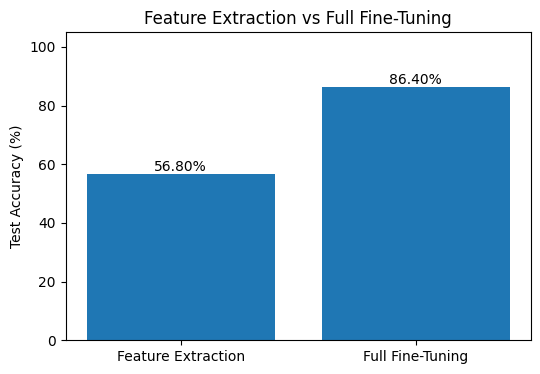

In [31]:
# Visualize the comparison

plt.figure(figsize=(6, 4))

routes = ["Feature Extraction", "Full Fine-Tuning"]

accuracies = [
    accuracy_a * 100,
    accuracy_b * 100
]

bars = plt.bar(routes, accuracies)

plt.bar_label(bars, fmt="%.2f%%")

plt.ylabel("Test Accuracy (%)")
plt.title("Feature Extraction vs Full Fine-Tuning")
plt.ylim(0, 105)

plt.show()

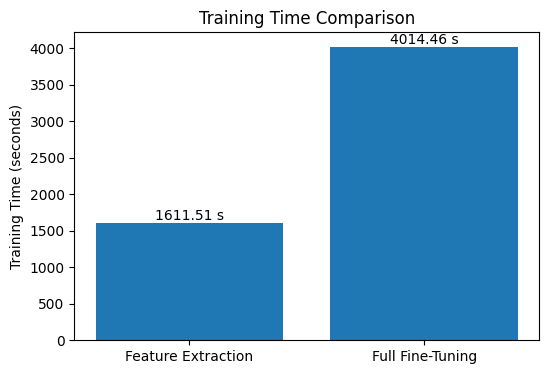

In [32]:
# Compare training time

plt.figure(figsize=(6, 4))

bars = plt.bar(
    routes,
    [training_time_a, training_time_b]
)

plt.bar_label(bars, fmt="%.2f s")

plt.ylabel("Training Time (seconds)")
plt.title("Training Time Comparison")

plt.show()

In [33]:
# Full fine-tuning is expected to achieve better accuracy because
# all pretrained layers can adapt to emotion-specific features.
# Feature extraction is expected to train faster because only
# the classification layers require gradient updates.

## Level 5: Debrief

Before landing, Mission Control wants to know where Mary still gets confused. Use your **best model** (Route B unless your results say otherwise).

## Tasks
1. Get predictions on the test set with trainer.predict(...) and convert logits topredicted labels with np.argmax.
2. Print a classification_report from sklearn.metrics with target_names=LABELS.
3. Print **5 test texts the model got wrong** , each with its true emotion and its predicted emotion.
4. In a comment: which emotion has the lowest score, and what might explain it? (Hint:look back at your Level 0 counts.)

In [34]:
# Select the best model and obtain predictions

if accuracy_b >= accuracy_a:

    best_trainer = trainer_b
    best_model = model_b
    best_route = "Route B: Full Fine-Tuning"

else:

    model_b.to("cpu")

    trainer_b.optimizer = None
    trainer_b.lr_scheduler = None

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    best_trainer = trainer_a
    best_model = model_a.to(device)
    best_route = "Route A: Feature Extraction"

print("Selected best model:", best_route)

prediction_output = best_trainer.predict(test_tokenized)

predicted_labels = np.argmax(
    prediction_output.predictions,
    axis=-1
)

true_labels = prediction_output.label_ids

print("Number of predictions:", len(predicted_labels))

print(
    f"Test accuracy: "
    f"{accuracy_score(true_labels, predicted_labels) * 100:.2f}%"
)


Selected best model: Route B: Full Fine-Tuning


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Number of predictions: 500
Test accuracy: 86.40%


In [35]:
# Print classification report

print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        true_labels,
        predicted_labels,
        labels=list(range(6)),
        target_names=LABELS,
        digits=4,
        zero_division=0
    )
)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     sadness     0.8889    0.9444    0.9158       144
         joy     0.8835    0.9430    0.9123       193
        love     0.6818    0.5000    0.5769        30
       anger     0.8929    0.7812    0.8333        64
        fear     0.7742    0.8889    0.8276        54
    surprise     1.0000    0.0667    0.1250        15

    accuracy                         0.8640       500
   macro avg     0.8535    0.6874    0.6985       500
weighted avg     0.8658    0.8640    0.8503       500



In [36]:
# Print five incorrectly classified texts

wrong_indices = np.where(
    predicted_labels != true_labels
)[0]

print("Total incorrect predictions:", len(wrong_indices))

print("\nFirst five incorrectly classified examples:\n")

for i, idx in enumerate(wrong_indices[:5]):

    print(f"Incorrect example {i + 1}")

    print("Text:", test_raw[int(idx)]["text"])

    print(
        "True emotion:",
        id2label[int(true_labels[idx])]
    )

    print(
        "Predicted emotion:",
        id2label[int(predicted_labels[idx])]
    )

    print("-" * 70)

Total incorrect predictions: 68

First five incorrectly classified examples:

Incorrect example 1
Text: i used to be able to hang around talk with the cashier when i was putting away my money now i feel rushed and stressed if i take a second to fumble with the coins and put them in my purse
True emotion: anger
Predicted emotion: fear
----------------------------------------------------------------------
Incorrect example 2
Text: i feel like some of you have pains and you cannot imagine becoming passionate about the group or the idea that is causing pain
True emotion: joy
Predicted emotion: love
----------------------------------------------------------------------
Incorrect example 3
Text: i cant write a review for a book i adore unless i am feeling in the adoring mood at that moment
True emotion: love
Predicted emotion: joy
----------------------------------------------------------------------
Incorrect example 4
Text: i feel like that because for the most part i have accepted that th

In [37]:
# Identify the lowest-performing emotion

report = classification_report(
    true_labels,
    predicted_labels,
    labels=list(range(6)),
    target_names=LABELS,
    output_dict=True,
    zero_division=0
)

f1_scores = {
    emotion: report[emotion]["f1-score"]
    for emotion in LABELS
}

lowest_emotion = min(f1_scores, key=f1_scores.get)

print("F1-score for each emotion:\n")

for emotion in LABELS:
    print(f"{emotion:10s}: {f1_scores[emotion]:.4f}")

print("\nLowest performing emotion:", lowest_emotion)

print(f"F1-score: {f1_scores[lowest_emotion]:.4f}")

print(
    "Number of training examples:",
    emotion_counts[lowest_emotion]
)

F1-score for each emotion:

sadness   : 0.9158
joy       : 0.9123
love      : 0.5769
anger     : 0.8333
fear      : 0.8276
surprise  : 0.1250

Lowest performing emotion: surprise
F1-score: 0.1250
Number of training examples: 70


In [38]:
# The emotion with the lowest F1-score is identified above.
# A smaller number of training examples may make it difficult
# for the model to learn distinctive patterns for that emotion.
# Overlapping emotional expressions may also cause confusion.

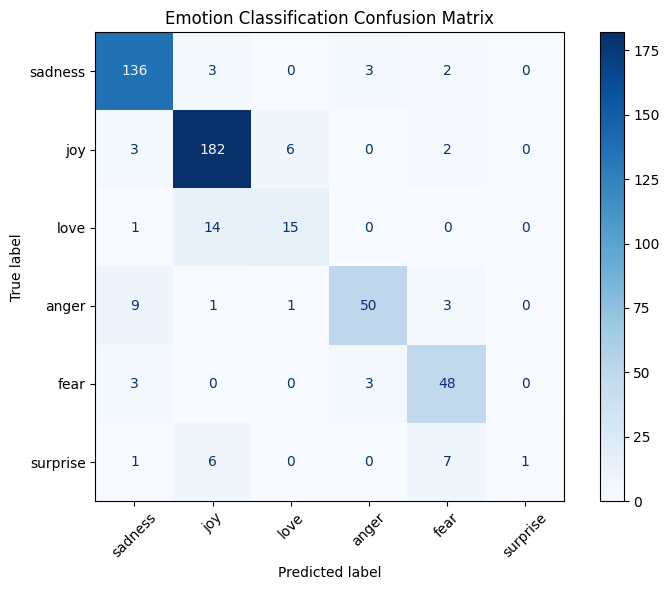

In [39]:
# Confusion matrix

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=list(range(6))
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LABELS
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Emotion Classification Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Level 6: Touchdown
Time to put Mary on the ship.

## Tasks
1. Save your best model **and** its tokenizer to a folder called
mary_final ( trainer.save_model(...) and tokenizer.save_pretrained(...)).
2. Build a pipeline("text-classification", model="mary_final", device=0)
(use device=-1 if you have no GPU) that loads from your saved folder.
3. Run it on these five **final transmissions** and print each message with its predictedemotion:

final_logs = [ "Reactor stable, crew fed, and the stars look beautiful tonight. I couldn't be happier.", "You were the first to believe in me out here. I will never forget that.", "Why was the airlock left open? Whose idea was that?!", "The oxygen readout is dropping and nobody is answering the comms.", "I can't believe it. The planet is actually there, right in front of us!",]expected = ["joy", "love", "anger", "fear", "surprise"]

4. Compare predictions to expected in code and count the matches. Then print the verdict:

* 5 out of 5: "PERFECT LANDING. Mary has become a specialist."
* 3 or 4 out of 5: "MISSION COMPLETE. Mary touched down safely."
* fewer than 3: "Rough landing. Go back to Level 4 and improve Mary."

If you land rough, tweak your Level 4 settings (more epochs, different learning rate) andtry again.

In [40]:
# Save the best model and tokenizer

SAVE_PATH = "mary_final"

best_trainer.save_model(SAVE_PATH)

tokenizer.save_pretrained(SAVE_PATH)

print("Best model:", best_route)
print("Model and tokenizer saved to:", SAVE_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model: Route B: Full Fine-Tuning
Model and tokenizer saved to: mary_final


In [41]:
import os

print(os.listdir(SAVE_PATH))

['tokenizer_config.json', 'model.safetensors', 'training_args.bin', 'tokenizer.json', 'config.json']


In [42]:
# Create a pipeline from the saved model

mary_classifier = pipeline(
    "text-classification",
    model="mary_final",
    tokenizer="mary_final",
    device=0 if torch.cuda.is_available() else -1
)

print("Mary's Emotion Monitor is ready!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Mary's Emotion Monitor is ready!


In [43]:
# Classify the final transmissions

final_logs = [
    "Reactor stable, crew fed, and the stars look beautiful tonight. I couldn't be happier.",

    "You were the first to believe in me out here. I will never forget that.",

    "Why was the airlock left open? Whose idea was that?!",

    "The oxygen readout is dropping and nobody is answering the comms.",

    "I can't believe it. The planet is actually there, right in front of us!"
]

expected = [
    "joy",
    "love",
    "anger",
    "fear",
    "surprise"
]

final_results = mary_classifier(
    final_logs,
    truncation=True,
    max_length=MAX_LEN
)

final_predictions = [
    result["label"]
    for result in final_results
]

for i, (log, result, true_emotion) in enumerate(
    zip(final_logs, final_results, expected)
):

    print(f"Transmission {i + 1}")
    print("Message:", log)

    print("Expected emotion:", true_emotion)
    print("Predicted emotion:", result["label"])

    print(f"Confidence: {result['score']:.4f}")

    print(
        "Result:",
        "Correct" if result["label"] == true_emotion
        else "Incorrect"
    )

    print("-" * 70)

Transmission 1
Message: Reactor stable, crew fed, and the stars look beautiful tonight. I couldn't be happier.
Expected emotion: joy
Predicted emotion: joy
Confidence: 0.9248
Result: Correct
----------------------------------------------------------------------
Transmission 2
Message: You were the first to believe in me out here. I will never forget that.
Expected emotion: love
Predicted emotion: joy
Confidence: 0.5121
Result: Incorrect
----------------------------------------------------------------------
Transmission 3
Message: Why was the airlock left open? Whose idea was that?!
Expected emotion: anger
Predicted emotion: fear
Confidence: 0.6609
Result: Incorrect
----------------------------------------------------------------------
Transmission 4
Message: The oxygen readout is dropping and nobody is answering the comms.
Expected emotion: fear
Predicted emotion: fear
Confidence: 0.6060
Result: Correct
----------------------------------------------------------------------
Transmission

In [44]:
# Count correct predictions and print mission verdict

matches = sum(
    predicted == actual
    for predicted, actual in zip(
        final_predictions,
        expected
    )
)

print("=" * 60)
print("FINAL MISSION RESULTS")
print("=" * 60)

print(f"Correct predictions: {matches} out of 5")

print(f"Final transmission accuracy: {matches / 5 * 100:.2f}%")

if matches == 5:

    print(
        "PERFECT LANDING. Mary has become a specialist."
    )

elif matches >= 3:

    print(
        "MISSION COMPLETE. Mary touched down safely."
    )

else:

    print(
        "Rough landing. Go back to Level 4 and improve Mary."
    )

FINAL MISSION RESULTS
Correct predictions: 2 out of 5
Final transmission accuracy: 40.00%
Rough landing. Go back to Level 4 and improve Mary.


In [45]:
print("=" * 65)
print("FINAL ASSIGNMENT SUMMARY")
print("=" * 65)

print("Model:", MODEL)
print("Dataset: dair-ai/emotion")

print("Number of emotion classes:", len(LABELS))

print("Training examples:", len(train_raw))
print("Testing examples:", len(test_raw))

print("Maximum sequence length:", MAX_LEN)

print(f"\nRoute A accuracy: {accuracy_a * 100:.2f}%")
print(f"Route B accuracy: {accuracy_b * 100:.2f}%")

print(f"\nRoute A training time: {training_time_a:.2f}s")
print(f"Route B training time: {training_time_b:.2f}s")

print("\nBest model:", best_route)

print(f"Best test accuracy: {max(accuracy_a, accuracy_b) * 100:.2f}%")

print(
    f"Macro F1-score: "
    f"{report['macro avg']['f1-score']:.4f}"
)

print(
    f"Weighted F1-score: "
    f"{report['weighted avg']['f1-score']:.4f}"
)

print("Lowest performing emotion:", lowest_emotion)

print(f"\nFinal transmission score: {matches}/5")

print("Saved model location:", SAVE_PATH)

print("=" * 65)

FINAL ASSIGNMENT SUMMARY
Model: distilbert-base-uncased
Dataset: dair-ai/emotion
Number of emotion classes: 6
Training examples: 2000
Testing examples: 500
Maximum sequence length: 128

Route A accuracy: 56.80%
Route B accuracy: 86.40%

Route A training time: 1611.51s
Route B training time: 4014.46s

Best model: Route B: Full Fine-Tuning
Best test accuracy: 86.40%
Macro F1-score: 0.6985
Weighted F1-score: 0.8503
Lowest performing emotion: surprise

Final transmission score: 2/5
Saved model location: mary_final


Submission: Share your **Colab notebook link** (set to Anyone with the link can view ), with all outputs visible.

See you at touchdown, Crew!!